<a href="https://colab.research.google.com/github/yuvasrisugu2008-maker/ITA0515--COMPUTER-VISION/blob/main/exp%2037.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving flower.jpg to flower (13).jpg


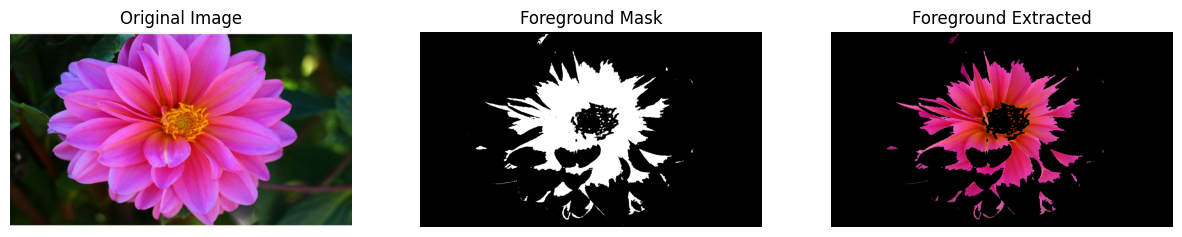

Foreground extraction completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def foreground_subtraction():

    # Upload image
    uploaded = files.upload()
    filename = next(iter(uploaded))

    # Read image
    image = cv2.imread(filename)

    if image is None:
        raise ValueError("Unable to read image.")

    # Convert image to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Define foreground color range
    # Example: Red color
    lower1 = np.array([0, 100, 100])
    upper1 = np.array([10, 255, 255])

    lower2 = np.array([160, 100, 100])
    upper2 = np.array([179, 255, 255])

    # Detect red color
    mask1 = cv2.inRange(hsv, lower1, upper1)
    mask2 = cv2.inRange(hsv, lower2, upper2)

    # Combine masks
    mask = cv2.bitwise_or(mask1, mask2)

    # Extract foreground
    foreground = cv2.bitwise_and(
        image, image, mask=mask
    )

    # Display results
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Foreground Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(foreground, cv2.COLOR_BGR2RGB))
    plt.title("Foreground Extracted")
    plt.axis("off")

    plt.show()

    # Save result
    cv2.imwrite("foreground_extracted.jpg", foreground)

    print("Foreground extraction completed!")

    files.download("foreground_extracted.jpg")

foreground_subtraction()
